# Manual spherical MC test

This notebook initializes a uniform mono-energetic electron distribution and mono-energetic photons. The photon packets are created manually and passed directly to `propagate_batch`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import nonthradsim.Constants as C
from nonthradsim.grid import Grid
from nonthradsim.particle import Particle
from nonthradsim.sampling import sample_manual_photons
from nonthradsim.mc import propagate_batch
from nonthradsim.observer import plot_bands

In [8]:
# Uniform spherical electron distribution at one Lorentz factor.
radius = 1e15
grid = Grid(dimension=1, dx=radius / 101, n_mesh=101)
electron_density = 1e9
gamma0 = 1e3
particle = Particle(
    grid, mass=C.me, charge=-1,
    gm_min=gamma0 / 1.02, gm_max=gamma0 * 1.02, n_spectrum=3,
)
particle.value[:] = 0
dgm = np.gradient(particle.gm)
particle.value[:, 1] = electron_density / dgm[1]

print('radius:', grid.radius)
print('electron gamma grid:', particle.gm)
print('electron density:', np.sum(particle.value * dgm, axis=-1)[0])

radius: 1000000000000000.0
electron gamma grid: [ 980.39215686 1000.         1020.        ]
electron density: 999999999.9999999


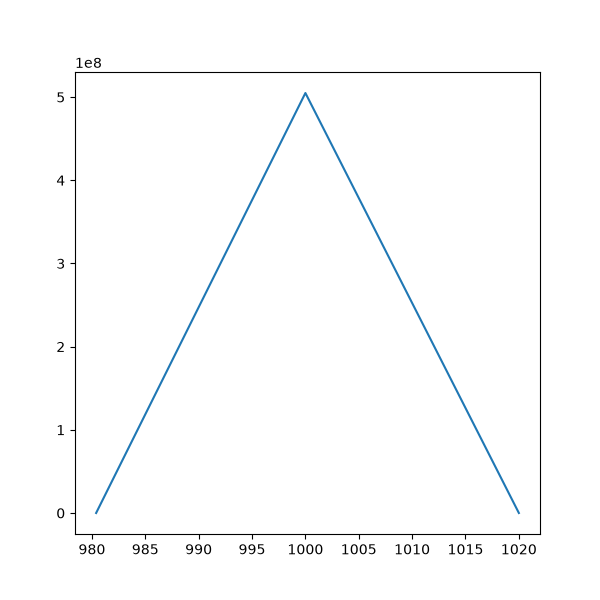

In [38]:
plt.figure(figsize=(6, 6))
plt.plot(particle.gm, particle.value[0], label='electron spectrum')

In [ ]:
# Manually define photon positions, energies, directions, and weights.
rng = np.random.default_rng(123)
n_packets = 100000
r = radius * rng.random(n_packets) ** (1 / 3)
position_direction = rng.normal(size=(n_packets, 3))
position_direction /= np.linalg.norm(position_direction, axis=1)[:, None]
position = r[:, None] * position_direction

photon_energy = 1e-9
energy = np.full(n_packets, photon_energy)
weight = np.ones(n_packets)
packets = sample_manual_photons(
    position=position,
    energy=energy,
    weight=weight,
    seed=456,
)

Gamma_E = 4 * photon_energy* gamma0 / (C.me * C.c ** 2)
print('Gamma_E:', Gamma_E)
print('initial packets:', len(packets['energy']))
print('initial energy:', packets['energy'][0])

Gamma_E: 14.657194264711807
initial packets: 100000
initial energy: 3e-09


In [21]:
# Manually call the vectorized MC propagation.
escaped = propagate_batch(
    grid,
    particle,
    packets,
    seed=42,
)
scattered = escaped['n_scatter'] > 0
print('escaped packets:', len(escaped['energy']))
print('scattered packets:', scattered.sum())
print('scattering fraction:', scattered.mean())
print('mean scatter number:', escaped['n_scatter'].mean())

RuntimeError: MC batch reached max_steps before all photons escaped

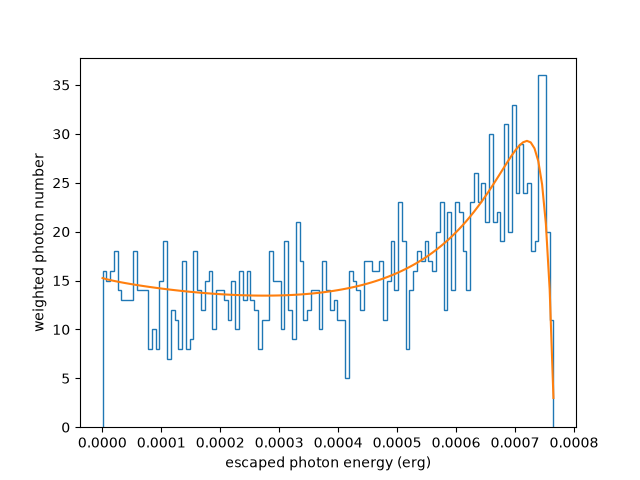

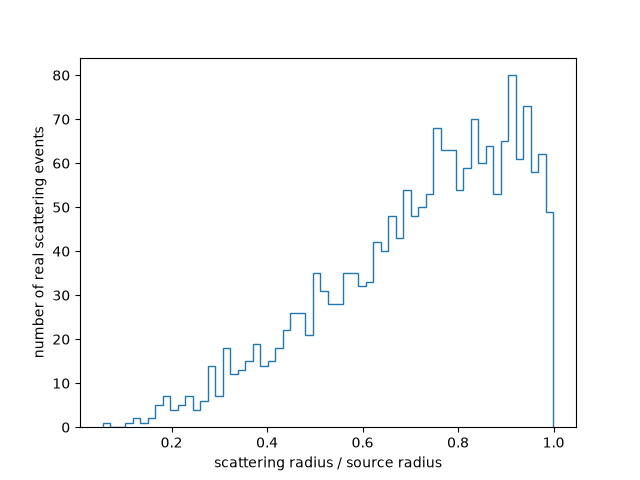

In [19]:
# Inspect the energy redistribution and scattering locations.
%matplotlib ipympl

mask = escaped['n_scatter'] ==1
# energy_edges = np.logspace(np.log10(photon_energy[mask] / 10), -3, 120)
energy_edges = np.linspace(escaped['energy'][mask].min(), escaped['energy'][mask].max(), 120)

E1 = energy_edges/gamma0 / (C.me * C.c ** 2)
a1= E1 * gamma0
q = E1 / Gamma_E / (1 - E1)
Spec = (2 * q * np.log(q) + (1 + 2 * q) * (1 - q) + (a1/gamma0)**2 / 2 / (1 - a1/gamma0) * (1-q))

plt.figure()
plt.hist(
    escaped['energy'],
    bins=energy_edges,
    weights=escaped['weight'],
    histtype='step'
)
plt.plot(energy_edges, Spec / Spec.sum() * escaped['weight'].sum() / 10)
# plt.xscale('log')
plt.xlabel('escaped photon energy (erg)')
plt.ylabel('weighted photon number')
plt.show()

plt.figure()
plt.hist(escaped['scatter_radius'] / grid.radius, bins=60,histtype= 'step')
plt.xlabel('scattering radius / source radius')
plt.ylabel('number of real scattering events')
plt.show()

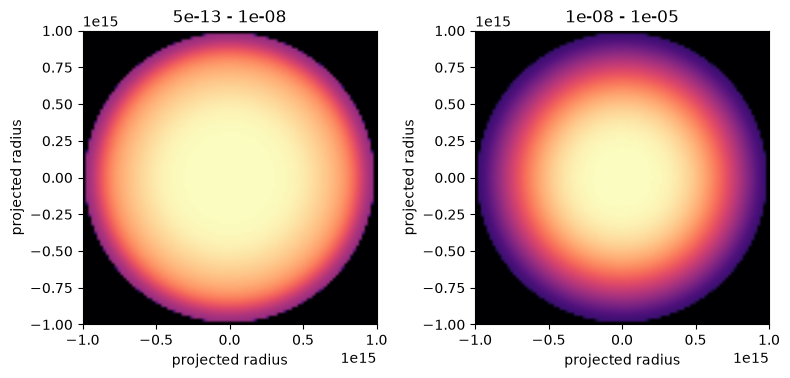

In [6]:
# The final map is also made directly from the manually propagated packets.
bands = [(photon_energy / 2, 1e-8), (1e-8, 1e-5)]
fig, axes = plot_bands(
    escaped,
    grid.radius,
    energy_edges,
    bands,
    image_size=101,
    radial_bins=32,
    kernel_width=4,
)
plt.show()